# 01 · David Romero Nina — Volumen de tráfico

**Pregunta central del proyecto:** ¿cómo detectar a tiempo comportamientos
anómalos en el tráfico de red del laboratorio para que la mesa de TI reaccione
antes de que se conviertan en incidentes?

**Mi dimensión:** ¿cuánto tráfico mueve el laboratorio, cómo se reparte y
cuánto moverá a continuación?

| | U1 (batch, este notebook) | U2 (streaming, Grafana) |
|---|---|---|
| Indicador | bytes por hora y por día | bytes por minuto |
| Predicción | total de la próxima hora | bytes del minuto siguiente |
| Fuente | Data Lake Gold (TRCU.csv) | Kafka `trafico-flujos` → Spark |

In [1]:
import sys
sys.path.insert(0, "/jobs")
sys.path.insert(0, "/notebooks")

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from analisis_comun import cargar, metricas_streaming, modelo_horario, perfil_horario, picos, resumen
from comun import crear_spark

spark = crear_spark("nb-01-david")
silver, gold = cargar(spark)
IND = "bytes"

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 00:50:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Descriptivo: ¿cuánto tráfico hay?

In [2]:
print(resumen(gold, IND).to_string())

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


                     bytes
minutos       3.475100e+04
total         4.402978e+08
promedio_min  1.267008e+04
mediana_min   2.098000e+03
p99_min       2.149290e+05
max_min       1.551150e+07


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


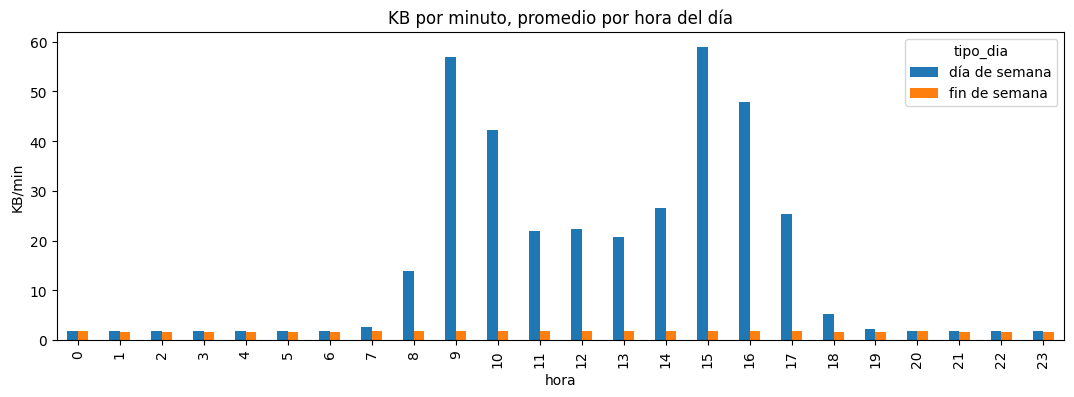

In [3]:
perfil = perfil_horario(gold, IND) / 1e3
perfil.plot(kind="bar", figsize=(13, 4), title="KB por minuto, promedio por hora del día")
plt.ylabel("KB/min")
plt.show()

## 2. Diagnóstico: ¿de dónde sale el volumen?

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


   servicio  MB_subida  MB_bajada  flujos
HTTPS (443)     232.49      69.33   22635
   otro UDP     121.05      11.12  367583
  HTTP (80)       2.06       1.22     336
   DNS (53)       0.72       0.41    2842
   otro TCP       1.80       0.12    3958


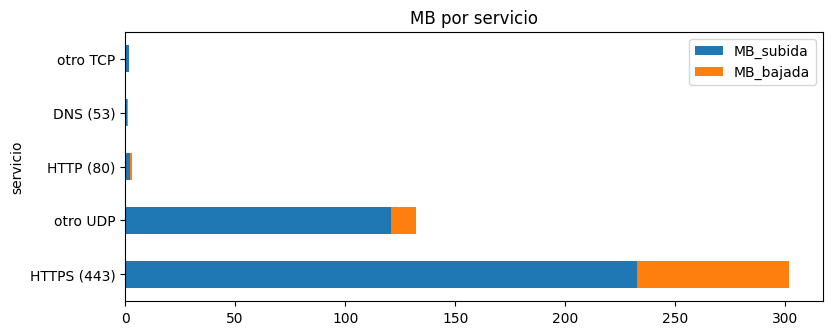

In [4]:
servicio = (F.when(F.col("dport").isin(443, 8443) | F.col("sport").isin(443, 8443), "HTTPS (443)")
            .when(F.col("dport").isin(80, 8080) | F.col("sport").isin(80, 8080), "HTTP (80)")
            .when((F.col("dport") == 53) | (F.col("sport") == 53), "DNS (53)")
            .when(F.col("ip_prot") == 17, "otro UDP")
            .otherwise("otro TCP"))
por_servicio = (silver.withColumn("servicio", servicio)
                .groupBy("servicio")
                .agg((F.sum("bytes_fwd") / 1e6).alias("MB_subida"), (F.sum("bytes_bwd") / 1e6).alias("MB_bajada"),
                     F.count("*").alias("flujos"))
                .orderBy(F.desc("MB_bajada")).toPandas())
print(por_servicio.round(2).to_string(index=False))
por_servicio.set_index("servicio")[["MB_subida", "MB_bajada"]].plot(kind="barh", stacked=True, figsize=(9, 3.5),
                                                                    title="MB por servicio")
plt.show()

In [5]:
externo = silver.select(
    (F.sum(F.when(~(F.col("src_interna") & F.col("dst_interna")), F.col("bytes_fwd") + F.col("bytes_bwd")))
     / F.sum(F.col("bytes_fwd") + F.col("bytes_bwd")) * 100).alias("pct_hacia_internet")).first()[0]
print(f"{externo:.1f} % de los bytes van o vienen de internet (no se quedan en la red del campus)")

79.8 % de los bytes van o vienen de internet (no se quedan en la red del campus)


In [6]:
print("Minutos más atípicos para su hora (candidatos a anomalía):")
print(picos(gold, IND).to_string(index=False))

Minutos más atípicos para su hora (candidatos a anomalía):


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


     ventana_inicio    bytes  media_de_esa_hora    z
2026-07-01 15:31:00 15511503            43436.4 37.1
2026-08-11 18:00:00  1440134             4128.2 35.7
2026-08-11 17:20:00  5561630            18659.8 34.8
2026-07-02 07:56:00   175680             2255.3 32.5
2026-07-08 19:28:00    78626             2037.6 30.6
2026-08-26 12:30:00  3073847            17060.3 28.9
2026-08-11 13:25:00  1864361            15698.4 22.7
2026-08-11 09:31:00  7592740            42092.5 21.7
2026-08-10 10:49:00  3089551            31815.3 19.9
2026-08-24 14:53:00  1683559            19867.4 19.6


## 3. Predictivo U1: total de bytes de la próxima hora (batch)

In [7]:
tabla, horas = modelo_horario(gold, IND)
print(f"{horas} horas consecutivas, división cronológica 80/20")
print(tabla.to_string())

26/10/30 00:50:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:27 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:28 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


...

26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:50:40 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

740 horas consecutivas, división cronológica 80/20
                          rmse         mae     r2  mejora_vs_persistencia_%
persistencia       1331261.262  532323.412  0.112                     0.000
linear_regression  1348086.947  771158.765  0.090                    -1.264
random_forest      1560690.111  628231.544 -0.220                   -17.234


## 4. U2: el modelo que corre en vivo (por minuto)
Entrenado por `entrenar_series.py` con validación cruzada temporal (3 cortes)
y evaluado en el último 20 % del tiempo, que no participó en ninguna decisión.

In [8]:
m, test, cv = metricas_streaming(IND)
print(f"Ganador: {m['ganador']} (escala {m['escala']}) | filas: {m['filas_total']:,}")
print(test.to_string())
print("\nBúsqueda de hiperparámetros (RMSE promedio de validación):")
print(cv.head(8).to_string(index=False))
print("\nVariables más importantes:", m["importancia_variables"])

Ganador: gbt (escala log) | filas: 26,316
                         rmse        mae     r2  mejora_vs_persistencia_%
persistencia       148264.084  24340.082 -0.334                      0.00
linear_regression  126099.722  14318.951  0.035                     14.95
random_forest      126944.747  13734.664  0.022                     14.38
gbt                124293.990  13996.716  0.062                     16.17

Búsqueda de hiperparámetros (RMSE promedio de validación):
           modelo   escala  regParam    rmse_cv  numTrees  maxDepth  maxIter
              gbt      log       NaN 144432.237       NaN       3.0     50.0
linear_regression      log       0.0 144550.188       NaN       NaN      NaN
linear_regression      log       0.1 144669.149       NaN       NaN      NaN
    random_forest      log       NaN 144681.825      40.0      10.0      NaN
    random_forest      log       NaN 144848.793      40.0       6.0      NaN
              gbt original       NaN 144952.607       NaN       3.

## 5. Conclusiones
- **Cola muy pesada:** la mediana es ~2 KB/min pero el p99 es ~215 KB/min y
  el máximo 15,5 MB en un minuto. Los minutos "normales" son tranquilos y el
  volumen se concentra en pocos picos (el más alto, 37 desviaciones sobre lo
  normal de su hora, el 1-jul a las 15:31).
- **~70 % de los bytes es HTTPS** y el 79,8 % va o viene de internet. En
  HTTPS la **subida (232 MB) supera a la bajada (69 MB)**: el equipo
  observado envía más de lo que recibe, algo a vigilar (respaldos, sincronización).
- **U1 (por hora): ningún modelo le gana a la persistencia** (LR −1,3 %,
  RF −17,2 %). A escala de hora el volumen es demasiado errático; esta es la
  razón para bajar a **minutos con rezagos** en U2.
- **U2 (por minuto):** con rezagos y escala log, el GBT sí le gana a la
  persistencia en test (+16,2 % RMSE, −43 % MAE). En Grafana (fila
  "Dimensión 1") se ve real vs predicción vs persistencia y el umbral de anomalía.